In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import requests
import re

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
movies = pd.read_csv("/content/movies.csv")
ratings = pd.read_csv("/content/ratings.csv")

print("Movies dataset:", movies.shape)
print("Ratings dataset:", ratings.shape)

display(movies.head())
display(ratings.head())

Movies dataset: (9742, 3)
Ratings dataset: (100836, 4)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [ ]:

print("MOVIES DATASET")
print("Shape:", movies.shape)
print("Columns:", movies.columns.tolist())
print("\nData types:")
print(movies.dtypes)
display(movies.head())

print("\nRATINGS DATASET")
print("Shape:", ratings.shape)
print("Columns:", ratings.columns.tolist())
print("\nData types:")
print(ratings.dtypes)
display(ratings.head())

print("\nStatistical summary of ratings:")
display(ratings["rating"].describe())



MOVIES DATASET
Shape: (9742, 3)
Columns: ['movieId', 'title', 'genres']

Data types:
movieId     int64
title      object
genres     object
dtype: object


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy



RATINGS DATASET
Shape: (100836, 4)
Columns: ['userId', 'movieId', 'rating', 'timestamp']

Data types:
userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931



Statistical summary of ratings:


,rating
count,100836.000000
mean,3.501557
std,1.042529
min,0.500000
25%,3.000000
50%,3.500000
75%,4.000000
max,5.000000


In [ ]:

print("Missing values in movies:")
display(movies.isnull().sum())

print("\nMissing values in ratings:")
display(ratings.isnull().sum())

print("\nDuplicate rows in movies:", movies.duplicated().sum())
print("Duplicate rows in ratings:", ratings.duplicated().sum())

print("\nRating range:")
print("Minimum:", ratings["rating"].min())
print("Maximum:", ratings["rating"].max())

print("\nInvalid ratings:",
      (~ratings["rating"].between(0.5, 5.0)).sum())


Missing values in movies:


,0
movieId,0
title,0
genres,0



Missing values in ratings:


,0
userId,0
movieId,0
rating,0
timestamp,0



Duplicate rows in movies: 0
Duplicate rows in ratings: 0

Rating range:
Minimum: 0.5
Maximum: 5.0

Invalid ratings: 0


In [ ]:

movies_clean = movies.copy()
ratings_clean = ratings.copy()

# Remove duplicate rows
movies_clean = movies_clean.drop_duplicates()
ratings_clean = ratings_clean.drop_duplicates()

# Remove rows missing essential identifiers or ratings
movies_clean = movies_clean.dropna(
    subset=["movieId", "title", "genres"]
)
ratings_clean = ratings_clean.dropna(
    subset=["userId", "movieId", "rating"]
)

# Correct data types
movies_clean["movieId"] = movies_clean["movieId"].astype(int)
ratings_clean["movieId"] = ratings_clean["movieId"].astype(int)
ratings_clean["userId"] = ratings_clean["userId"].astype(int)
ratings_clean["rating"] = pd.to_numeric(
    ratings_clean["rating"], errors="coerce"
)

# Retain valid ratings on the MovieLens 0.5 to 5.0 scale
ratings_clean = ratings_clean[
    ratings_clean["rating"].between(0.5, 5.0)
].copy()

# Extract a four-digit year from titles ending in (YYYY)
movies_clean["year"] = pd.to_numeric(
    movies_clean["title"].str.extract(r"\((\d{4})\)\s*$")[0],
    errors="coerce"
)

print("Cleaned movies:", movies_clean.shape)
print("Cleaned ratings:", ratings_clean.shape)

print("\nRemaining missing values:")
print("Movies:\n", movies_clean.isnull().sum())
print("Ratings:\n", ratings_clean.isnull().sum())


Cleaned movies: (9742, 4)
Cleaned ratings: (100836, 4)

Remaining missing values:
Movies:
 movieId     0
title       0
genres      0
year       13
dtype: int64
Ratings:
 userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


In [ ]:

df = ratings_clean.merge(
    movies_clean,
    on="movieId",
    how="inner",
    validate="many_to_one"
)

print("Merged dataset shape:", df.shape)
display(df.head())

print("\nSummary:")
print("Unique movies rated:", df["movieId"].nunique())
print("Unique users:", df["userId"].nunique())
print("Total ratings:", len(df))
print("Unique genres field combinations:", df["genres"].nunique())


Merged dataset shape: (100836, 7)


,userId,movieId,rating,timestamp,title,genres,year
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance,1995.0
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller,1995.0
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,1995.0
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,1995.0



Summary:
Unique movies rated: 9724
Unique users: 610
Total ratings: 100836
Unique genres field combinations: 951


In [ ]:

movie_stats = (
    df.groupby(["movieId", "title", "year", "genres"], dropna=False)
      .agg(
          average_rating=("rating", "mean"),
          rating_count=("rating", "count"),
          rating_median=("rating", "median"),
          rating_std=("rating", "std")
      )
      .reset_index()
)

print("Movie-level statistics:")
display(movie_stats.head())

print("\nMovies with the most ratings:")
display(
    movie_stats.sort_values("rating_count", ascending=False)
    [["title", "average_rating", "rating_count"]]
    .head(10)
)


Movie-level statistics:


,movieId,title,year,genres,average_rating,rating_count,rating_median,rating_std
0,1,Toy Story (1995),1995.0,Adventure|Animation|Children|Comedy|Fantasy,3.920930,215,4.0,0.834859
1,2,Jumanji (1995),1995.0,Adventure|Children|Fantasy,3.431818,110,3.5,0.881713
2,3,Grumpier Old Men (1995),1995.0,Comedy|Romance,3.259615,52,3.0,1.054823
3,4,Waiting to Exhale (1995),1995.0,Comedy|Drama|Romance,2.357143,7,3.0,0.852168
4,5,Father of the Bride Part II (1995),1995.0,Comedy,3.071429,49,3.0,0.907148



Movies with the most ratings:


,title,average_rating,rating_count
314,Forrest Gump (1994),4.164134,329
277,"Shawshank Redemption, The (1994)",4.429022,317
257,Pulp Fiction (1994),4.197068,307
510,"Silence of the Lambs, The (1991)",4.161290,279
1938,"Matrix, The (1999)",4.192446,278
224,Star Wars: Episode IV - A New Hope (1977),4.231076,251
418,Jurassic Park (1993),3.750000,238
97,Braveheart (1995),4.031646,237
507,Terminator 2: Judgment Day (1991),3.970982,224
461,Schindler's List (1993),4.225000,220


In [ ]:

rating_series = df["rating"]

statistics = pd.Series({
    "Count": rating_series.count(),
    "Mean": rating_series.mean(),
    "Median": rating_series.median(),
    "Mode": rating_series.mode().iloc[0],
    "Variance": rating_series.var(),
    "Standard Deviation": rating_series.std(),
    "Minimum": rating_series.min(),
    "Maximum": rating_series.max(),
    "Range": rating_series.max() - rating_series.min()
})

display(statistics.to_frame("Value").round(3))

print("Rating distribution:")
display(rating_series.value_counts().sort_index())


,Value
Count,100836.000
Mean,3.502
Median,3.500
Mode,4.000
Variance,1.087
Standard Deviation,1.043
Minimum,0.500
Maximum,5.000
Range,4.500


Rating distribution:


,count
rating,
0.5,1370
1.0,2811
1.5,1791
2.0,7551
2.5,5550
3.0,20047
3.5,13136
4.0,26818
4.5,8551


In [ ]:

genre_df = df[df["genres"] != "(no genres listed)"].copy()

genre_df["genre"] = genre_df["genres"].str.split("|")
genre_df = genre_df.explode("genre")

genre_stats = (
    genre_df.groupby("genre")
    .agg(
        average_rating=("rating", "mean"),
        rating_count=("rating", "count"),
        unique_movies=("movieId", "nunique")
    )
    .reset_index()
)

# Exclude genres with very little evidence from the main comparison
MIN_RATINGS = 100

genre_stats_filtered = genre_stats[
    genre_stats["rating_count"] >= MIN_RATINGS
].copy()

display(
    genre_stats_filtered.sort_values(
        "average_rating", ascending=False
    ).round(3)
)


,genre,average_rating,rating_count,unique_movies
9,Film-Noir,3.920,870,85
17,War,3.808,4859,381
6,Documentary,3.798,1219,438
5,Crime,3.658,16681,1196
7,Drama,3.656,41928,4349
13,Mystery,3.632,7674,573
2,Animation,3.630,6988,610
11,IMAX,3.618,4145,158
18,Western,3.584,1930,167
12,Musical,3.564,4138,333


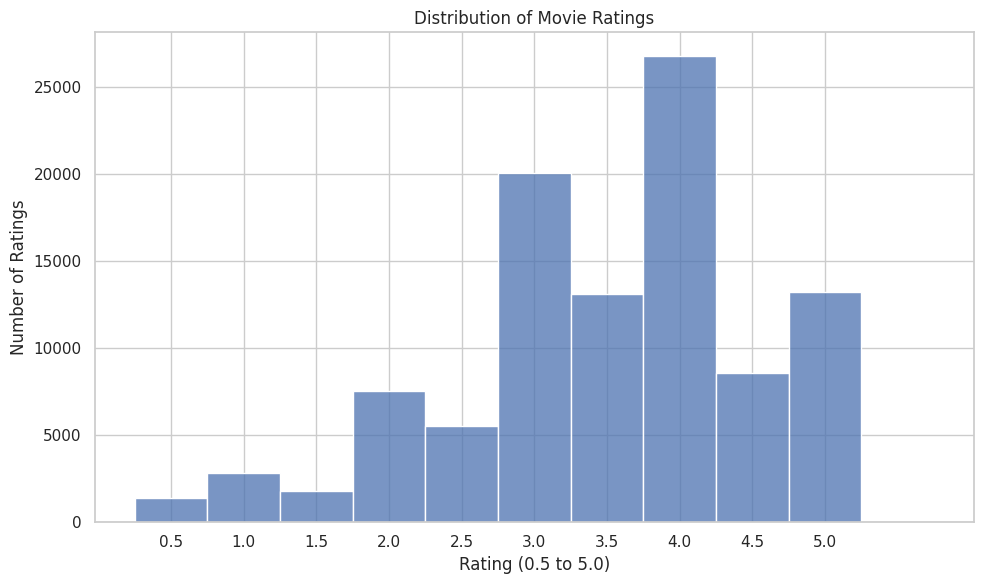

In [ ]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="rating",
    bins=np.arange(0.25, 5.76, 0.5),
    kde=False
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating (0.5 to 5.0)")
plt.ylabel("Number of Ratings")
plt.xticks(np.arange(0.5, 5.1, 0.5))
plt.tight_layout()
plt.show()


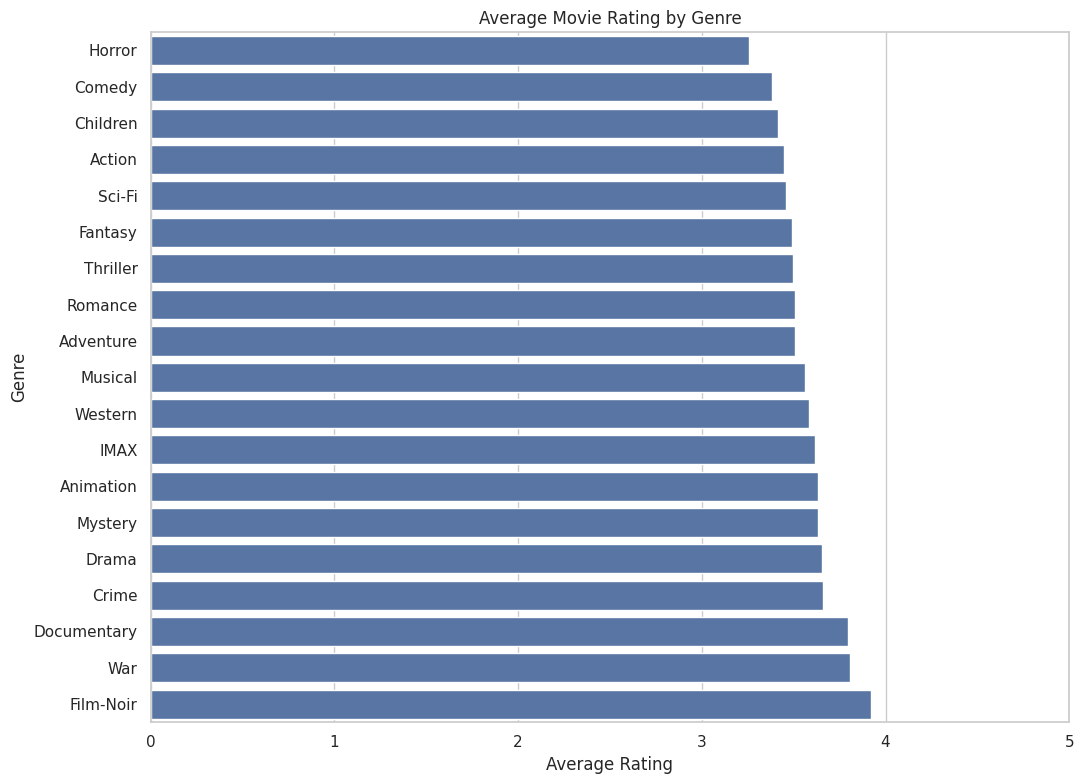

In [ ]:

plot_data = genre_stats_filtered.sort_values("average_rating")

plt.figure(figsize=(11, 8))

sns.barplot(
    data=plot_data,
    x="average_rating",
    y="genre"
)

plt.title("Average Movie Rating by Genre")
plt.xlabel("Average Rating")
plt.ylabel("Genre")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()


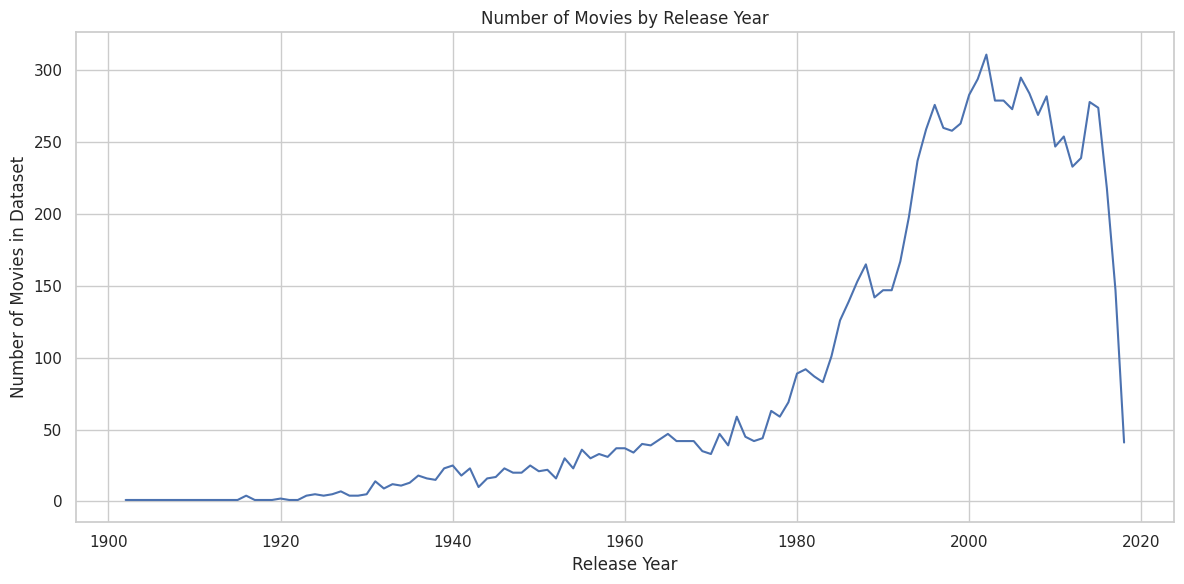

In [ ]:

year_counts = (
    movies_clean.dropna(subset=["year"])
    .groupby("year")["movieId"]
    .nunique()
    .reset_index(name="movie_count")
)

year_counts = year_counts[
    year_counts["year"].between(1900, 2020)
]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=year_counts,
    x="year",
    y="movie_count"
)

plt.title("Number of Movies by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies in Dataset")
plt.tight_layout()
plt.show()


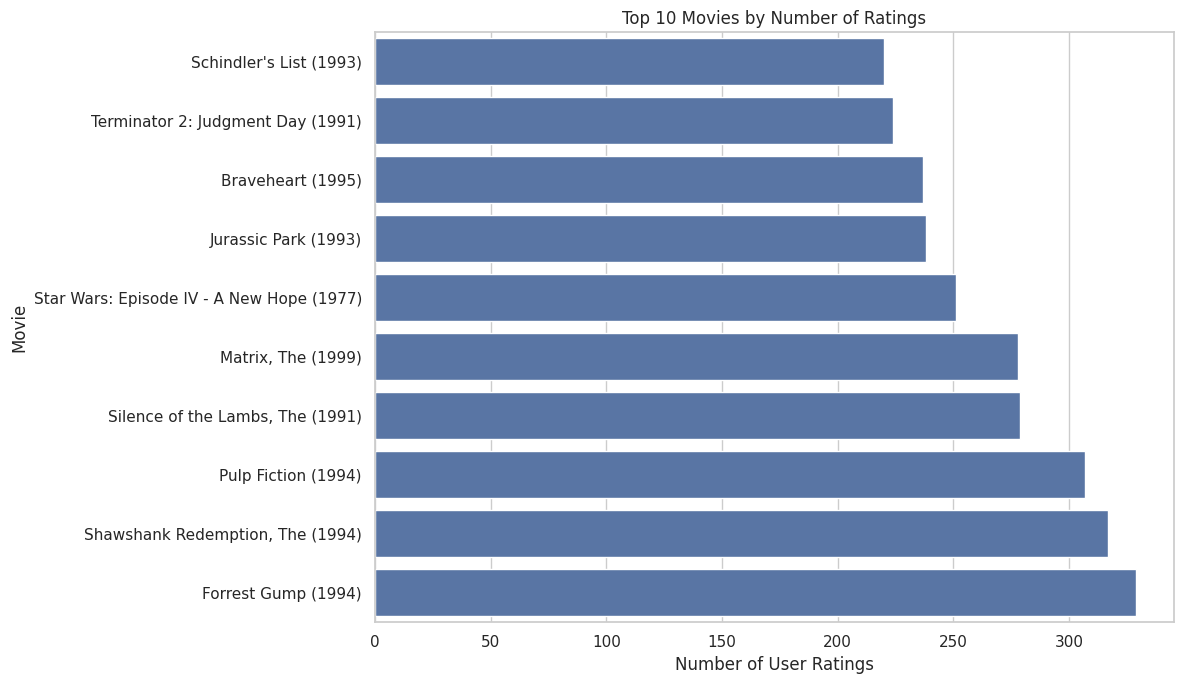

In [ ]:

top_movies = (
    movie_stats.sort_values("rating_count", ascending=False)
    .head(10)
    .sort_values("rating_count")
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_movies,
    x="rating_count",
    y="title"
)

plt.title("Top 10 Movies by Number of Ratings")
plt.xlabel("Number of User Ratings")
plt.ylabel("Movie")
plt.tight_layout()
plt.show()


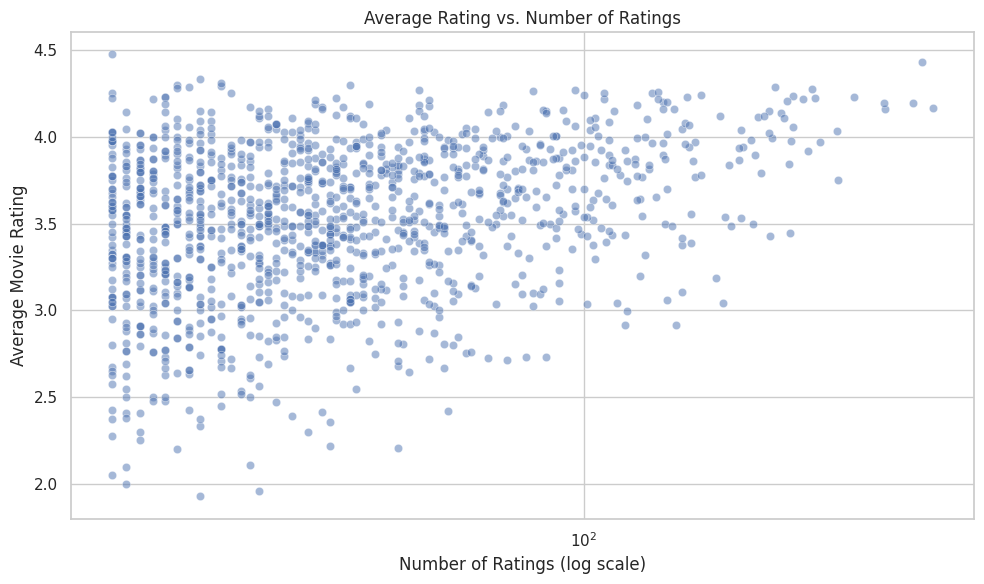

Pearson correlation: 0.303


In [ ]:

# Use movies with at least 20 ratings for a more stable comparison
scatter_data = movie_stats[
    movie_stats["rating_count"] >= 20
].copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=scatter_data,
    x="rating_count",
    y="average_rating",
    alpha=0.5
)

plt.xscale("log")
plt.title("Average Rating vs. Number of Ratings")
plt.xlabel("Number of Ratings (log scale)")
plt.ylabel("Average Movie Rating")
plt.tight_layout()
plt.show()

correlation = scatter_data[
    ["rating_count", "average_rating"]
].corr().iloc[0, 1]

print("Pearson correlation:", round(correlation, 3))


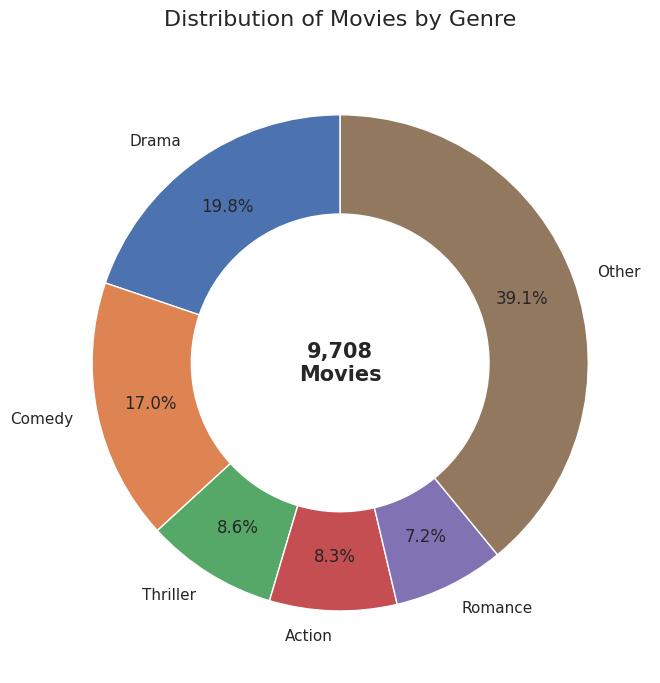

In [ ]:
# Remove movies without a valid genre classification
genre_data = movies_clean[
    movies_clean["genres"].notna()
    & (movies_clean["genres"] != "(no genres listed)")
].copy()

# Split multiple genres and count each genre separately
genre_counts = (
    genre_data.assign(
        genre=genre_data["genres"].str.split("|")
    )
    .explode("genre")
    .groupby("genre")["movieId"]
    .nunique()
    .sort_values(ascending=False)
)

# Keep the top 5 genres and combine the rest
top_genres = genre_counts.head(5)
other_count = genre_counts.iloc[5:].sum()

if other_count > 0:
    top_genres.loc["Other"] = other_count

# Create the donut chart
fig, ax = plt.subplots(figsize=(9, 7))

wedges, texts, autotexts = ax.pie(
    top_genres.values,
    labels=top_genres.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={"width": 0.4, "edgecolor": "white"}
)

ax.set_title(
    "Distribution of Movies by Genre",
    fontsize=16,
    pad=20
)

ax.text(
    0, 0,
    f"{genre_data['movieId'].nunique():,}\nMovies",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# Export cleaned movie data
movies_clean.to_csv(
    "/content/cleaned_movies.csv",
    index=False
)

# Export cleaned ratings data
ratings_clean.to_csv(
    "/content/cleaned_ratings.csv",
    index=False
)

print("Both datasets exported successfully!")

Both datasets exported successfully!
